# Signal analysis

### Goals of the notebook
- Analyse the correlation betweern each information on the input vector (meta data, demographic data, radiomics ) with the correctness label


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
c2_correct_cf = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom_corrected/effusion/cv_results_correct_cf/cf_1/fold_0_predictions.csv")
c2_correct_cf_emb = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom_corrected/effusion/cv_results_correct_cf_emb/cf_1/fold_0_predictions.csv")
c2_extended_correct_cf = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom_corrected/effusion/cv_results_extended_correct_cf/cf_1/fold_0_predictions.csv")
c2_gt_routing = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom_corrected/effusion/cv_results_gt_routing/cf_1/fold_0_predictions.csv")
c2_unmatched_cf = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom_corrected/effusion/cv_results_unmatched/cf_1/fold_0_predictions.csv")
c2_match_train_cf = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom_corrected/effusion/cv_results/cf_1/fold_0_predictions.csv")

In [3]:
c2_correct_cf

,path,effusion_prob,effusion_true,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,MLP_M2_prob,MLP_M3_prob,MLP_M4_prob,MLP_M5_prob,MLP_M6_prob,MLP_MCF1_prob,MLP_MCF2_prob,MLP_MCF3_prob,MLP_MCF4_prob,MLP_MCF5_prob
0,CheXpert-v1.0-small/train/patient00008/study1/...,0.989880,1.0,-0.001258,-0.002985,0.004605,0.001783,0.038349,0.398952,-0.001282,...,0.879254,0.953001,0.981341,0.995202,0.903154,0.982857,0.991487,0.971747,0.980251,0.974674
1,CheXpert-v1.0-small/train/patient00012/study2/...,0.061508,0.0,-0.001186,-0.001275,0.003886,0.003654,-0.103998,0.123141,-0.001299,...,0.865218,0.960525,0.874409,0.902470,0.964169,0.934990,0.917110,0.925275,0.747463,0.895425
2,CheXpert-v1.0-small/train/patient00012/study1/...,0.029149,0.0,-0.001169,-0.001558,0.002563,0.004094,-0.134588,0.212008,-0.001316,...,0.801848,0.969861,0.933140,0.948807,0.985416,0.955292,0.995667,0.950444,0.926186,0.976097
3,CheXpert-v1.0-small/train/patient00019/study4/...,0.948374,1.0,-0.001191,-0.001380,0.003970,0.002725,0.089560,0.564539,-0.001307,...,0.981792,0.996702,0.985075,0.998346,0.998485,0.973110,0.999893,0.997790,0.987468,0.986332
4,CheXpert-v1.0-small/train/patient00049/study3/...,0.166953,0.0,-0.001179,-0.002039,0.002705,0.002814,-0.034566,0.176318,-0.001297,...,0.736414,0.541716,0.713559,0.822815,0.525250,0.776051,0.746513,0.837814,0.785793,0.773048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9026,CheXpert-v1.0-small/train/patient47326/study10...,0.995934,1.0,-0.001196,-0.002324,0.003113,0.002768,0.062728,0.129214,-0.001298,...,0.932279,0.991655,0.997257,0.998112,0.998297,0.981828,0.998227,0.988854,0.994741,0.995524
9027,CheXpert-v1.0-small/train/patient47326/study3/...,0.997899,1.0,-0.001202,-0.002493,0.004686,0.003029,0.049496,0.735655,-0.001268,...,0.976248,0.995063,0.996299,0.998382,0.995732,0.982878,0.996273,0.995342,0.996820,0.995721
9028,CheXpert-v1.0-small/train/patient47326/study9/...,0.993435,1.0,-0.001207,-0.002522,0.004752,0.002649,0.004848,0.318023,-0.001271,...,0.988459,0.992778,0.966187,0.982348,0.998545,0.982069,0.994385,0.970226,0.991751,0.971105
9029,CheXpert-v1.0-small/train/patient47343/study4/...,0.254230,0.0,-0.001193,-0.000748,0.004452,0.002485,0.093880,0.295449,-0.001299,...,0.828251,0.457626,0.306621,0.479488,0.441649,0.584095,0.674289,0.886912,0.376186,0.433604


## Extract the four signal groups from each df
For every loaded df, split its columns into:
- **attribute vector**: original (non-delta, non-embedding) radiomics/demographic/meta attributes
- **delta-A vector**: `delta_*` columns (counterfactual shift in each attribute)
- **prob**: the disease prediction probability column
- **embedding vector**: `emb_*` columns

In [7]:
DISEASE = 'effusion'

# Columns that are bookkeeping/meta rather than model input attributes
META_COLS = {
    f'{DISEASE}_prob', f'{DISEASE}_pred', f'{DISEASE}_true',
    'correct', 'path', 'patient_id', 'cf_prob', 'cf_paths', 'margin',
}

def get_column_groups(df, disease=DISEASE):
    """Split a df's columns into (attribute_cols, delta_cols, prob_col, emb_cols)."""
    emb_cols = [c for c in df.columns if c.startswith('emb_')]
    delta_cols = [c for c in df.columns if c.startswith('delta_')]
    model_pred_cols = [c for c in df.columns if any(m in c for m in ['LR_', 'RF_', 'MLP_'])]
    meta_cols = [c for c in df.columns if c in META_COLS]

    attribute_cols = [
        c for c in df.columns
        if c not in emb_cols and c not in delta_cols
        and c not in model_pred_cols and c not in meta_cols
    ]

    prob_col = f'{disease}_prob'
    return attribute_cols, delta_cols, prob_col, emb_cols, meta_cols


def extract_signals(df, disease=DISEASE):
    """Return the attribute vector, delta-A vector, prob, and embedding vector for a df."""
    attribute_cols, delta_cols, prob_col, emb_cols, meta_cols = get_column_groups(df, disease)
    return {
        'attribute_vector': df[attribute_cols],
        'delta_vector': df[delta_cols],
        'prob': df[prob_col],
        'embedding_vector': df[emb_cols],
        'meta': df[meta_cols],
    }

In [19]:
dfs = {
    'correct_cf': c2_correct_cf,
    'correct_cf_emb': c2_correct_cf_emb,
    'extended_correct_cf': c2_extended_correct_cf,
    'gt_routing': c2_gt_routing,
    'unmatched_cf': c2_unmatched_cf,
    'match_train_cf': c2_match_train_cf,
}

signals = {name: extract_signals(df) for name, df in dfs.items()}
for name, s in signals.items():
    print(f"{name}: attribute_vector{s['attribute_vector'].shape}, "
          f"delta_vector{s['delta_vector'].shape}, "
          f"prob{s['prob'].shape}, "
          f"embedding_vector{s['embedding_vector'].shape}, "
          f"meta{s['meta'].shape}, ")

correct_cf: attribute_vector(9031, 1947), delta_vector(9031, 464), prob(9031,), embedding_vector(9031, 1024), meta(9031, 9), 
correct_cf_emb: attribute_vector(9031, 1947), delta_vector(9031, 464), prob(9031,), embedding_vector(9031, 1024), meta(9031, 9), 
extended_correct_cf: attribute_vector(9031, 2619), delta_vector(9031, 800), prob(9031,), embedding_vector(9031, 1024), meta(9031, 9), 
gt_routing: attribute_vector(9031, 1947), delta_vector(9031, 464), prob(9031,), embedding_vector(9031, 1024), meta(9031, 9), 
unmatched_cf: attribute_vector(9031, 1947), delta_vector(9031, 464), prob(9031,), embedding_vector(9031, 1024), meta(9031, 9), 
match_train_cf: attribute_vector(9031, 461), delta_vector(9031, 463), prob(9031,), embedding_vector(9031, 1024), meta(9031, 9), 


 17%|█▋        | 1/6 [01:12<06:04, 72.94s/it]

correct_cf: mean AUROC = 0.6305, std = 0.0302


 33%|███▎      | 2/6 [02:19<04:36, 69.13s/it]

correct_cf_emb: mean AUROC = 0.6198, std = 0.0267


/work3/s251710/thesis_env_new/lib64/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/work3/s251710/thesis_env_new/lib64/python3.9/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.

extended_correct_cf: mean AUROC = 0.6101, std = 0.0152


... (2 outputs left out)

 83%|████████▎ | 5/6 [12:32<02:23, 143.31s/it]

unmatched_cf: mean AUROC = 0.6301, std = 0.0322


100%|██████████| 6/6 [12:40<00:00, 126.83s/it]

match_train_cf: mean AUROC = 0.6022, std = 0.0278


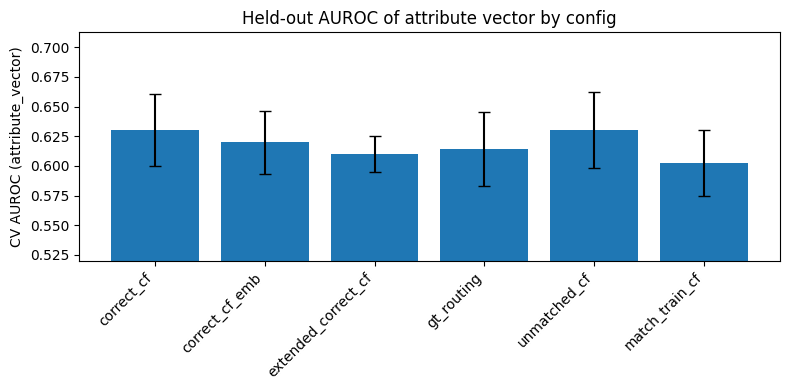

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from tqdm import tqdm

# --- compute held-out AUROC of delta_vector for each df ---
results = {}
for name, s in tqdm(signals.items()):
    X = s['attribute_vector'].values            # (n, n_delta_dims)
    y = s['meta']['correct'].values
    lr = LogisticRegression(max_iter=2000)
    # 5-fold CV, AUROC — held-out, so this reflects generalisation not memorisation
    scores = cross_val_score(lr, X, y, cv=5, scoring='roc_auc')
    print(f"{name}: mean AUROC = {scores.mean():.4f}, std = {scores.std():.4f}")
    results[name] = (scores.mean(), scores.std())

# --- plot ---
names = list(results.keys())
means = [results[n][0] for n in names]
stds  = [results[n][1] for n in names]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(names, means, yerr=stds, capsize=4)
ax.axhline(0.5, ls='--', c='gray', lw=1)   # chance line
ax.set_ylabel('CV AUROC (attribute_vector)')
ax.set_title('Held-out AUROC of attribute vector by config')
min = min(means) - max(stds) - 0.05
max = max(means) + max(stds) + 0.05
ax.set_ylim(min, max)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

 17%|█▋        | 1/6 [00:29<02:26, 29.31s/it]

correct_cf: mean AUROC = 0.7922, std = 0.0170


 33%|███▎      | 2/6 [01:24<02:58, 44.65s/it]

correct_cf_emb: mean AUROC = 0.8107, std = 0.0160


 50%|█████     | 3/6 [02:25<02:36, 52.22s/it]

extended_correct_cf: mean AUROC = 0.7466, std = 0.0568


... (2 outputs left out)

 83%|████████▎ | 5/6 [03:25<00:38, 38.24s/it]

unmatched_cf: mean AUROC = 0.7859, std = 0.0188


100%|██████████| 6/6 [03:54<00:00, 39.04s/it]

match_train_cf: mean AUROC = 0.7415, std = 0.0214


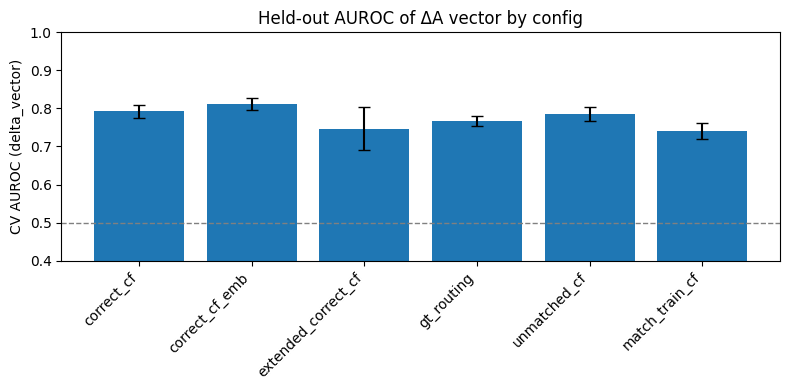

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from tqdm import tqdm

# --- compute held-out AUROC of delta_vector for each df ---
results = {}
for name, s in tqdm(signals.items()):
    X = s['delta_vector'].values            # (n, n_delta_dims)
    y = s['meta']['correct'].values
    lr = LogisticRegression(max_iter=2000)
    # 5-fold CV, AUROC — held-out, so this reflects generalisation not memorisation
    scores = cross_val_score(lr, X, y, cv=5, scoring='roc_auc')
    print(f"{name}: mean AUROC = {scores.mean():.4f}, std = {scores.std():.4f}")
    results[name] = (scores.mean(), scores.std())

# --- plot ---
names = list(results.keys())
means = [results[n][0] for n in names]
stds  = [results[n][1] for n in names]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(names, means, yerr=stds, capsize=4)
ax.axhline(0.5, ls='--', c='gray', lw=1)   # chance line
ax.set_ylabel('CV AUROC (delta_vector)')
ax.set_title('Held-out AUROC of ΔA vector by config')
ax.set_ylim(0.4, 1.0)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

100%|██████████| 6/6 [00:00<00:00, 25.52it/s]

correct_cf: mean AUROC = 0.7148, std = 0.0480
correct_cf_emb: mean AUROC = 0.6936, std = 0.0355
extended_correct_cf: mean AUROC = 0.7261, std = 0.0472
gt_routing: mean AUROC = 0.5844, std = 0.0308
unmatched_cf: mean AUROC = 0.7090, std = 0.0436
match_train_cf: mean AUROC = 0.7090, std = 0.0436


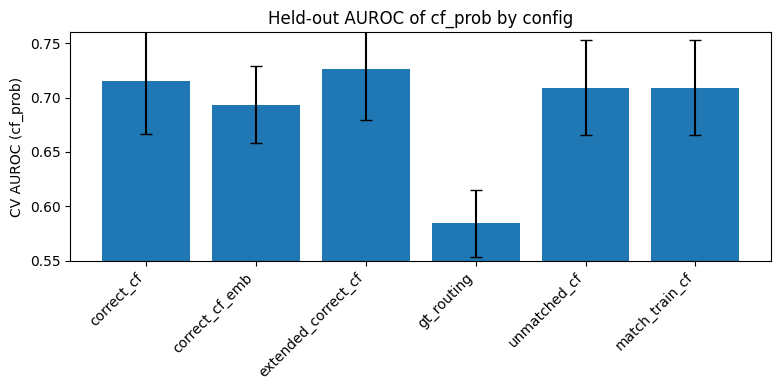

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from tqdm import tqdm

# --- compute held-out AUROC of delta_vector for each df ---
results = {}
for name, s in tqdm(signals.items()):
    X = s['meta']['cf_prob'].values.reshape(-1, 1)            # (n, 1)
    y = s['meta']['correct'].values
    lr = LogisticRegression(max_iter=2000)
    # 5-fold CV, AUROC — held-out, so this reflects generalisation not memorisation
    scores = cross_val_score(lr, X, y, cv=5, scoring='roc_auc')
    print(f"{name}: mean AUROC = {scores.mean():.4f}, std = {scores.std():.4f}")
    results[name] = (scores.mean(), scores.std())

# --- plot ---
names = list(results.keys())
means = [results[n][0] for n in names]
stds  = [results[n][1] for n in names]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(names, means, yerr=stds, capsize=4)
ax.axhline(0.5, ls='--', c='gray', lw=1)   # chance line
ax.set_ylabel('CV AUROC (cf_prob)')
ax.set_title('Held-out AUROC of cf_prob by config')
ax.set_ylim(0.55, 0.76)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

 17%|█▋        | 1/6 [01:07<05:37, 67.50s/it]

correct_cf: mean AUROC = 0.8152, std = 0.0197


 33%|███▎      | 2/6 [02:15<04:30, 67.73s/it]

correct_cf_emb: mean AUROC = 0.8152, std = 0.0197


 50%|█████     | 3/6 [03:34<03:38, 72.83s/it]

extended_correct_cf: mean AUROC = 0.8234, std = 0.0064


... (2 outputs left out)

 83%|████████▎ | 5/6 [05:48<01:09, 69.45s/it]

unmatched_cf: mean AUROC = 0.8152, std = 0.0197


100%|██████████| 6/6 [06:56<00:00, 69.45s/it]

match_train_cf: mean AUROC = 0.8152, std = 0.0197


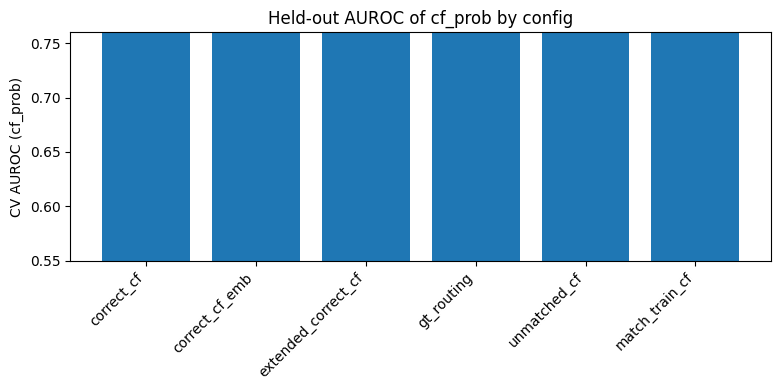

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from tqdm import tqdm

# --- compute held-out AUROC of delta_vector for each df ---
results = {}
for name, s in tqdm(signals.items()):
    X = s['embedding_vector'].values          # (n, 1)
    y = s['meta']['correct'].values
    lr = LogisticRegression(max_iter=2000)
    # 5-fold CV, AUROC — held-out, so this reflects generalisation not memorisation
    scores = cross_val_score(lr, X, y, cv=5, scoring='roc_auc')
    print(f"{name}: mean AUROC = {scores.mean():.4f}, std = {scores.std():.4f}")
    results[name] = (scores.mean(), scores.std())

# --- plot ---
names = list(results.keys())
means = [results[n][0] for n in names]
stds  = [results[n][1] for n in names]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(names, means, yerr=stds, capsize=4)
ax.axhline(0.5, ls='--', c='gray', lw=1)   # chance line
ax.set_ylabel('CV AUROC (cf_prob)')
ax.set_title('Held-out AUROC of cf_prob by config')
ax.set_ylim(0.55, 0.76)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()